# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [135]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [136]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('breast_data.csv')  # Ganti 'data.csv' dengan nama file dataset Anda
display(df.head())


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [137]:
print("Jumlah baris dan kolom:", df.shape)
print(f"missing value:\n{df.isnull().sum()}")
print(f"duplicate value:\n{df.duplicated().sum()}")

Jumlah baris dan kolom: (569, 33)
missing value:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst       

In [138]:
df = df.drop(columns=['Unnamed: 32', 'id'])
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


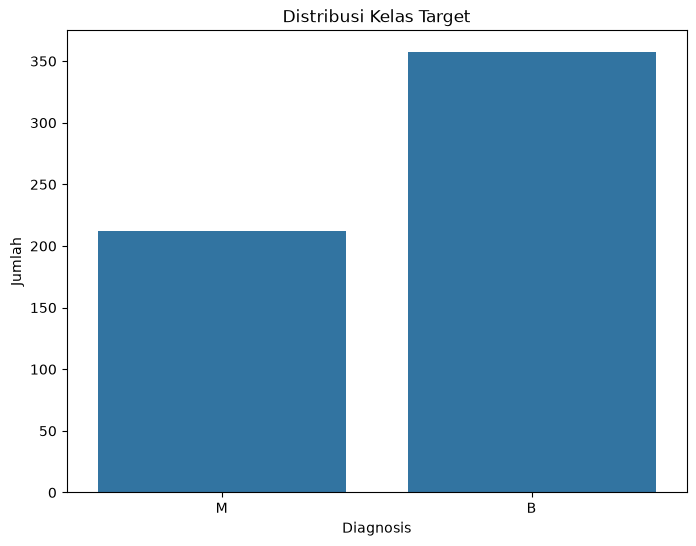

persentage kelas target:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [139]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='diagnosis')
plt.title('Distribusi Kelas Target')
plt.xlabel('Diagnosis')
plt.ylabel('Jumlah')
plt.show()

print(f'persentage kelas target:\n{df["diagnosis"].value_counts(normalize=True) * 100}')

walaupun terjadi ketidakseimbangan kelas, menurut saya ini masih dalam kategori wajar untuk dataset medis

In [140]:
df_clean = df.copy()
df_clean

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [141]:
"""
Cell generated by Data Wrangler.
"""
def clean_data(df_clean):
    # Replace all instances of "M" with "1" in column: 'diagnosis'
    df_clean['diagnosis'] = df_clean['diagnosis'].str.replace("M", "1", case=False, regex=False)
    # Replace all instances of "b" with "0" in column: 'diagnosis'
    df_clean['diagnosis'] = df_clean['diagnosis'].str.replace("b", "0", case=False, regex=False)
    return df_clean

df_clean = clean_data(df_clean.copy())
df_clean["diagnosis"] = df_clean["diagnosis"].astype(int)

df_clean.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<Figure size 1200x800 with 0 Axes>

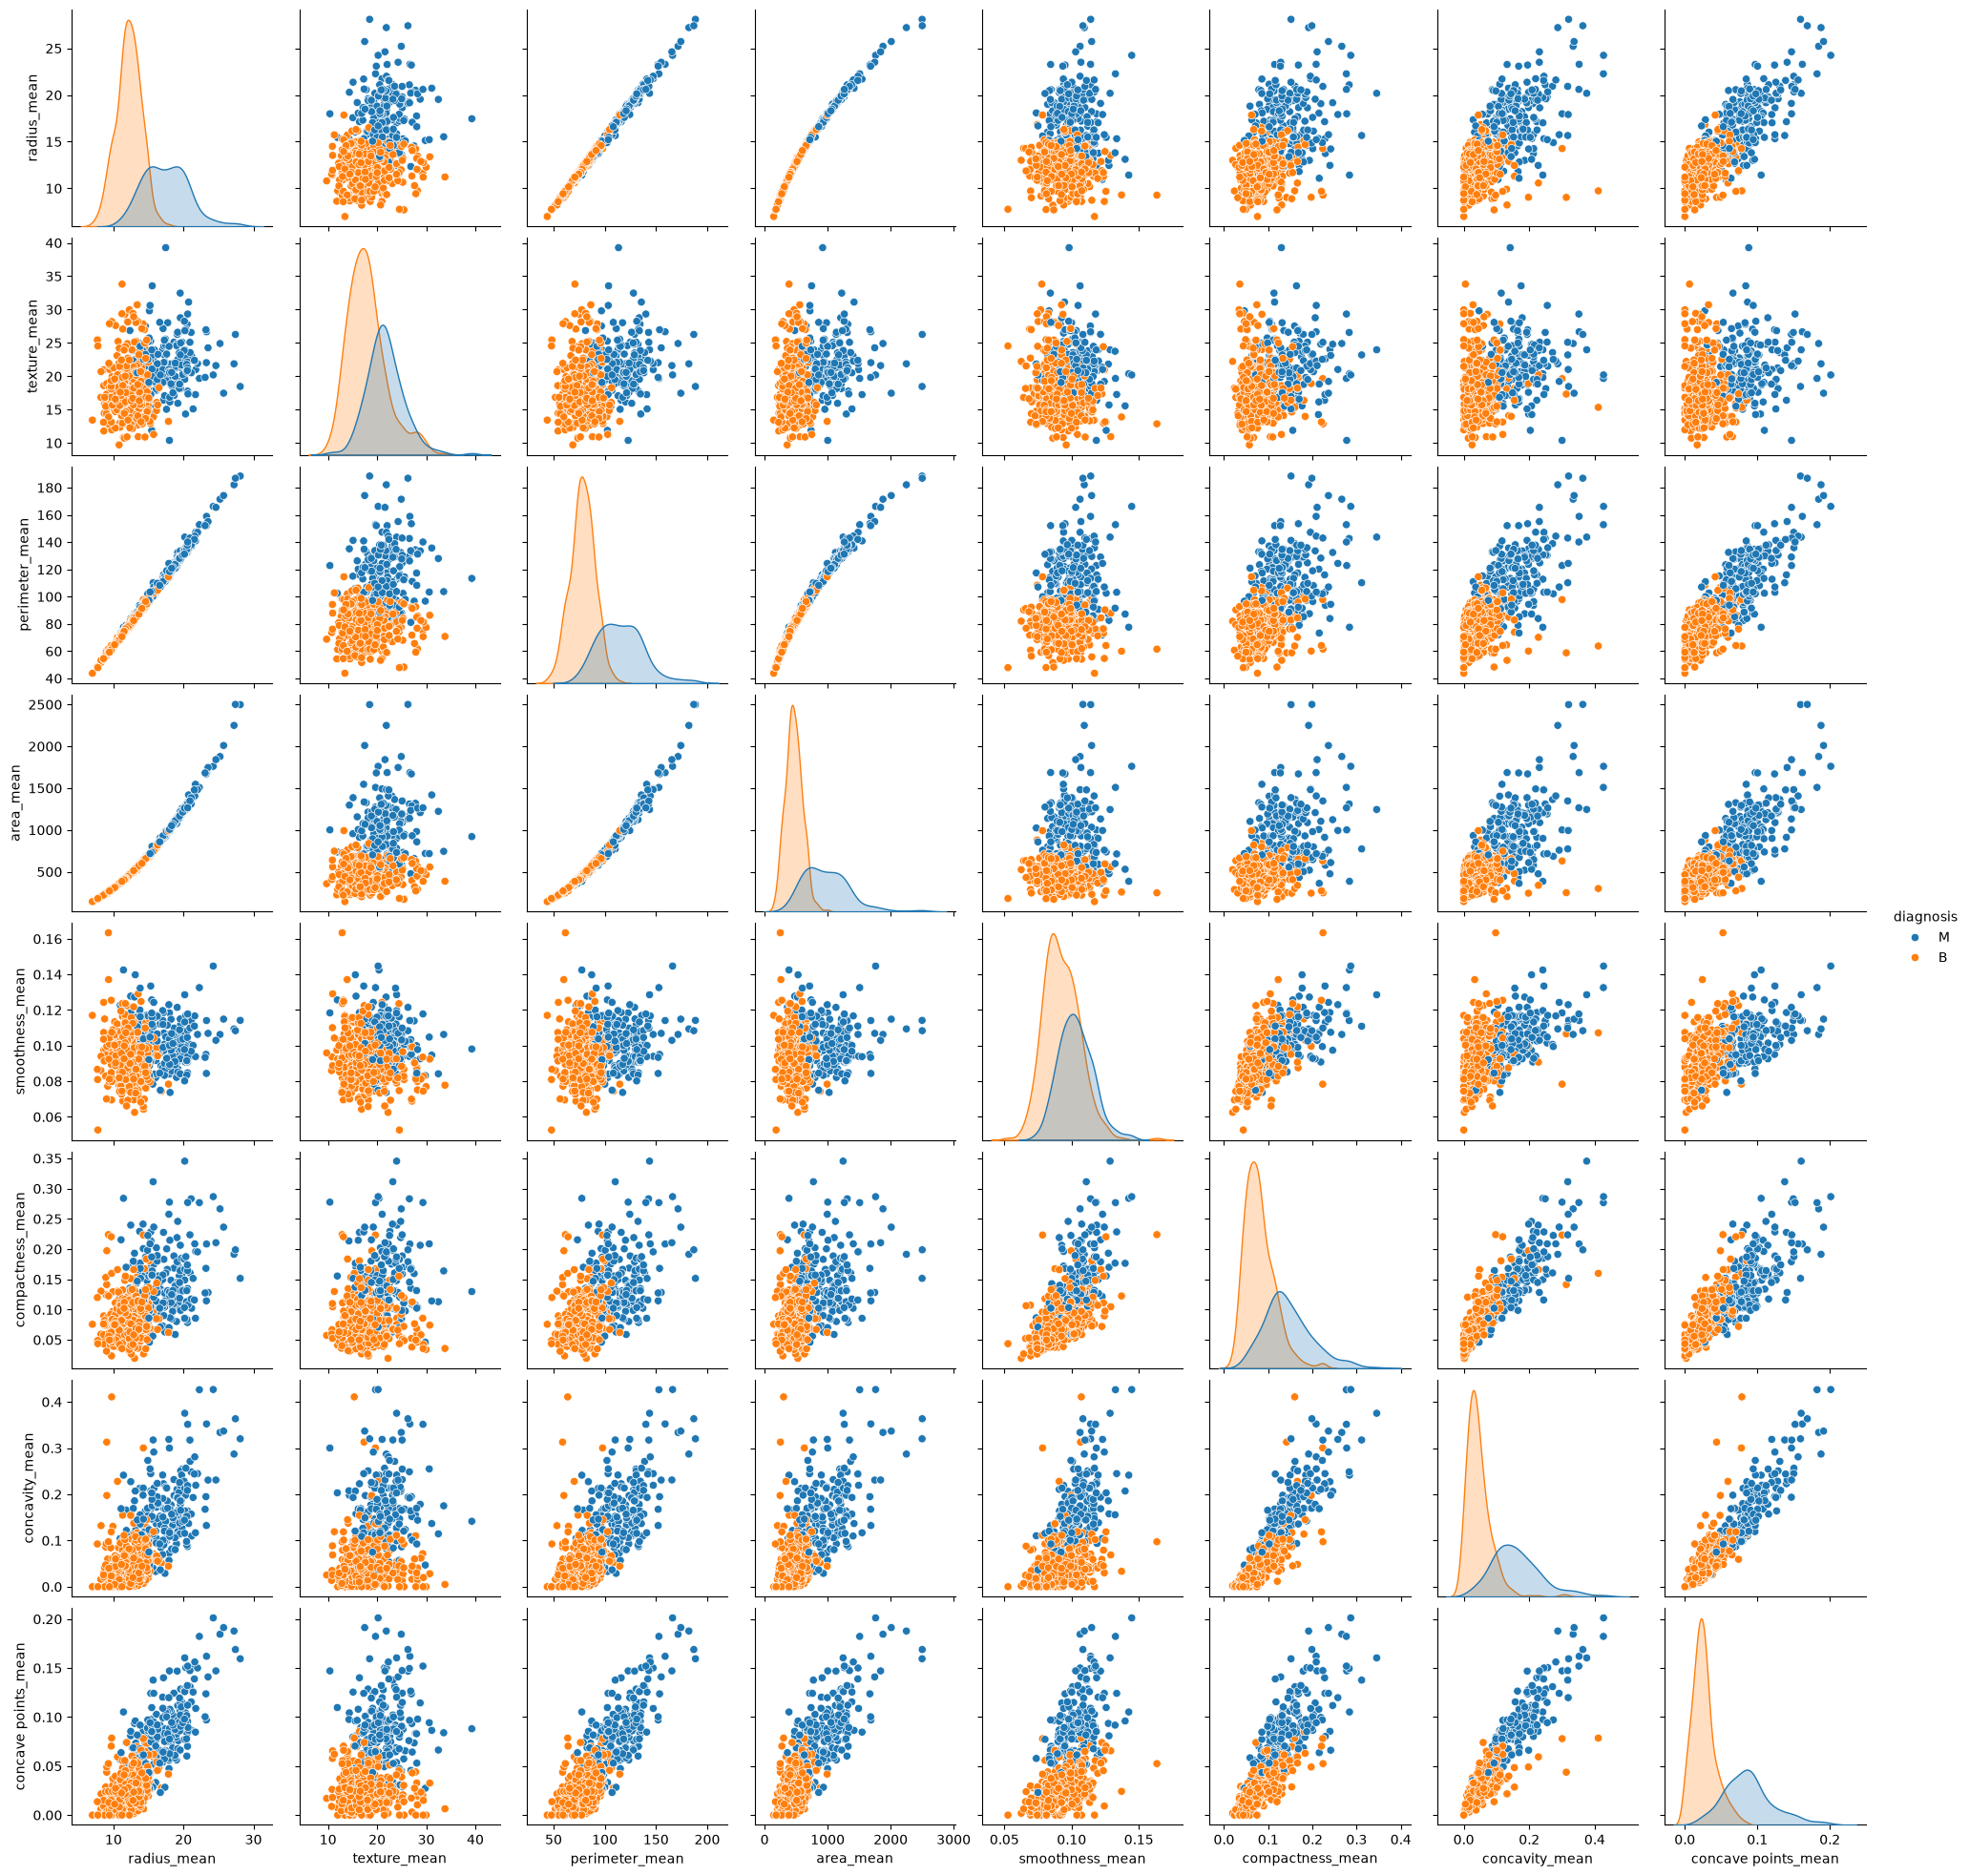

In [142]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.

plt.figure(figsize=(12, 8))
# Menggunakan pairplot untuk melihat hubungan antar fitur

numeric_cols = df.select_dtypes(include=['number']).columns

sns.pairplot(df, hue='diagnosis', vars=numeric_cols[:8]) 
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [143]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

print("Jumlah missing value:")
print(df_clean.isnull().sum())
print("Jumlah duplicate rows:")
print(df_clean.duplicated().sum())

Jumlah missing value:
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64
Jumlah duplicate rows:
0


In [144]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# 1. Pisahkan fitur dan target terlebih dahulu
X = df_clean.drop(columns=['diagnosis'])  # Ganti dengan nama target Anda
y = df_clean['diagnosis']

# 2. Seleksi kolom secara aman
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['number']).columns

# 3. Inisialisasi encoder
ohe = OneHotEncoder(sparse_output=False, drop='first')

# 4. Susun preprocessor (tanpa tanda kutip pada variabel ohe)
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', ohe, categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ],
    remainder='passthrough'
)

# 5. Output berupa DataFrame pandas
preprocessor.set_output(transform='pandas')

# 6. Transformasi data fitur
X_processed = preprocessor.fit_transform(X)

In [145]:
X_processed.head()

,num__radius_mean,num__texture_mean,num__perimeter_mean,num__area_mean,num__smoothness_mean,num__compactness_mean,num__concavity_mean,num__concave points_mean,num__symmetry_mean,num__fractal_dimension_mean,...,num__radius_worst,num__texture_worst,num__perimeter_worst,num__area_worst,num__smoothness_worst,num__compactness_worst,num__concavity_worst,num__concave points_worst,num__symmetry_worst,num__fractal_dimension_worst
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


In [146]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42, stratify=y)


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [159]:
# Inisialisasi dan latih model SVC dengan kernel='linear' menggunakan train set (yang sudah discaling).
from sklearn.svm import SVC 

model_svc_linear = SVC(kernel='linear', random_state=42, class_weight='balanced', C=1.0)  # class_weight='balanced' untuk menangani ketidakseimbangan kelas
model_svc_linear.fit(X_train, y_train)

y_pred_linear = model_svc_linear.predict(X_test)


,precision,recall,f1-score,support
0,0.973,0.986,0.979,72.000
1,0.976,0.952,0.964,42.000
accuracy,0.974,0.974,0.974,0.974
macro avg,0.974,0.969,0.972,114.000
weighted avg,0.974,0.974,0.974,114.000


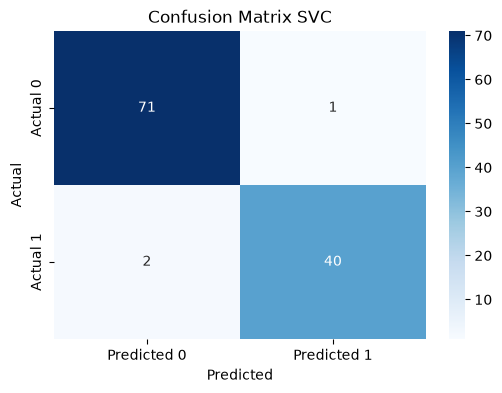

In [164]:
# Evaluasi model SVC pada test set.
from sklearn.metrics import classification_report, confusion_matrix

report_dict = classification_report(y_test, y_pred_linear, output_dict=True)


df_report_linear = pd.DataFrame(report_dict).T.round(3)


confusion_matrix_svc = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix_svc, 
            annot=True, fmt='d', 
            cmap='Blues', 
            xticklabels=['Predicted 0', 'Predicted 1'], 
            yticklabels=['Actual 0', 'Actual 1'],
            )
plt.title('Confusion Matrix SVC')
plt.xlabel('Predicted')
plt.ylabel('Actual')

display(df_report_linear)



## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [161]:
# Inisialisasi dan latih model SVC dengan kernel='rbf' menggunakan train set.
# Gunakan nilai hyperparameter lain (C) yang sama seperti model Linear di atas, agar perbandingan adil.

from sklearn.svm import SVC 

model_svc_rbf = SVC(kernel='rbf', random_state=42, class_weight='balanced', C=1.0)  # class_weight='balanced' untuk menangani ketidakseimbangan kelas
model_svc_rbf.fit(X_train, y_train)

y_pred_rbf = model_svc_rbf.predict(X_test)


,precision,recall,f1-score,support
0,0.986,0.986,0.986,72.000
1,0.976,0.976,0.976,42.000
accuracy,0.982,0.982,0.982,0.982
macro avg,0.981,0.981,0.981,114.000
weighted avg,0.982,0.982,0.982,114.000


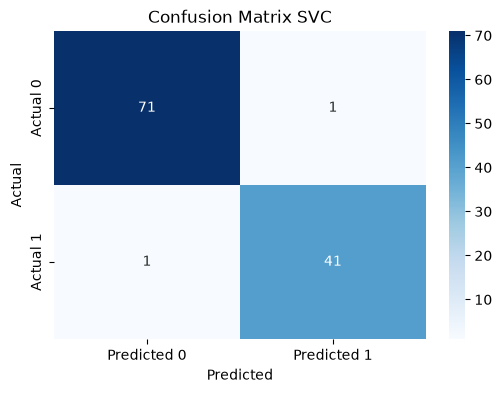

In [163]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

# Evaluasi model SVC pada test set.
from sklearn.metrics import classification_report, confusion_matrix

report_dict = classification_report(y_test, y_pred_rbf, output_dict=True)



df_report_rbf = pd.DataFrame(report_dict).T.round(3)


confusion_matrix_svc = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix_svc, 
            annot=True, fmt='d', 
            cmap='Blues', 
            xticklabels=['Predicted 0', 'Predicted 1'], 
            yticklabels=['Actual 0', 'Actual 1'],
            )
plt.title('Confusion Matrix SVC')
plt.xlabel('Predicted')
plt.ylabel('Actual')

display(df_report_rbf)



gaada perbedaan signifikan antara model linear dan rbf, ini bisa jadi karena dataset ini memang cukup mudah dipisahkan secara linear. 

## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [170]:
# Latih beberapa model SVC (kernel RBF) dengan variasi nilai C,
# misalnya 0.01, 0.1, 1, 10, 100.
# Gunakan gamma='scale' atau nilai gamma tetap agar perbandingan fokus pada pengaruh C.

list_C = [0.01, 0.1, 1, 10, 100]
dict_accuracy_train = {}
dict_accuracy_test = {}

In [171]:
# Hitung akurasi pada train set dan test set untuk setiap nilai C yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
for C in list_C:
    model_svc_rbf = SVC(kernel='rbf', random_state=42, class_weight='balanced', C=C, gamma='scale')
    model_svc_rbf.fit(X_train, y_train)
    y_pred_rbf = model_svc_rbf.predict(X_train)
    accuracy = (y_pred_rbf == y_train).mean()
    dict_accuracy_train[C] = accuracy

    y_pred_rbf = model_svc_rbf.predict(X_test)
    accuracy = (y_pred_rbf == y_test).mean()
    dict_accuracy_test[C] = accuracy


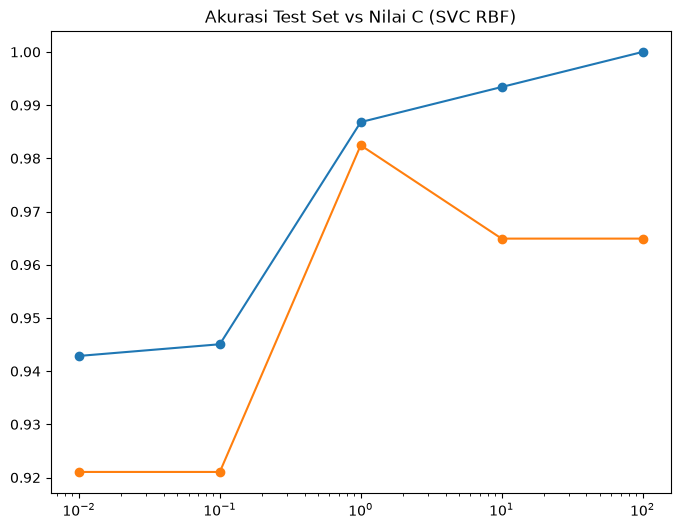

In [174]:
# Plot grafik akurasi training vs testing terhadap nilai C (gunakan sumbu x logaritmik) dalam satu chart.
# Amati pada nilai C berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

plt.figure(figsize=(8, 6))
plt.plot(list_C, list(dict_accuracy_train.values()), marker='o', label='Train Accuracy')    
plt.plot(list_C, list(dict_accuracy_test.values()), marker='o', label='Test Accuracy')
plt.xscale('log')
plt.title('Akurasi Test Set vs Nilai C (SVC RBF)')
plt.show()

gejala overfitting mulai terjadi saat nilai c = 10, akurasi training terus naik, sementara akurasi testing mulai stagnan bahkan menurun.

# 4. Evaluasi Model

In [183]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model kernel Linear dan RBF.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

print("================ Metrik Evaluasi Model SVC Kernel Linear: ==================")
print(df_report_linear)
print()
print("================ Metrik Evaluasi Model SVC Kernel RBF: ==================")
print(df_report_rbf)
print()

#selisih tiap metric
df_diff = df_report_linear[['precision', 'recall', 'f1-score']].subtract(df_report_rbf[['precision', 'recall', 'f1-score']])
print("================ Selisih Metrik Evaluasi (Linear - RBF): ==================")
print(df_diff)



================ Metrik Evaluasi Model SVC Kernel Linear: ==================
              precision  recall  f1-score  support  selisih f1-score
0                 0.973   0.986     0.979   72.000            -0.007
1                 0.976   0.952     0.964   42.000            -0.012
accuracy          0.974   0.974     0.974    0.974            -0.008
macro avg         0.974   0.969     0.972  114.000            -0.009
weighted avg      0.974   0.974     0.974  114.000            -0.008

================ Metrik Evaluasi Model SVC Kernel RBF: ==================
              precision  recall  f1-score  support
0                 0.986   0.986     0.986   72.000
1                 0.976   0.976     0.976   42.000
accuracy          0.982   0.982     0.982    0.982
macro avg         0.981   0.981     0.981  114.000
weighted avg      0.982   0.982     0.982  114.000

================ Selisih Metrik Evaluasi (Linear - RBF): ==================
              precision  recall  f1-score
0        

RBF unggul sedikit dibandingkan Linear dalam mayoritas metric, hanya seimbang pada precision class `1` dengan diff = 0 

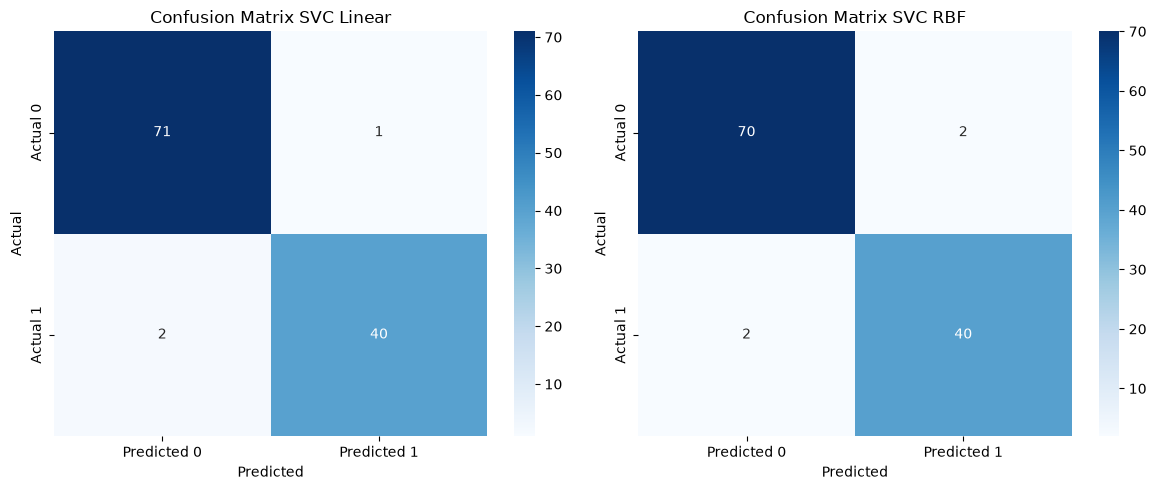

In [187]:
# Tampilkan Confusion Matrix untuk model kernel Linear dan RBF dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
cm_linear = confusion_matrix(y_test, model_svc_linear.predict(X_test))
cm_rbf = confusion_matrix(y_test, model_svc_rbf.predict(X_test))

plt.figure(figsize=(12, 5))

# Subplot 1: SVC Linear
plt.subplot(1, 2, 1)
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix SVC Linear')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Subplot 2: Model Kedua (misal cm_rbf)
plt.subplot(1, 2, 2)
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix SVC RBF')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()



kernel linaear berhasil mendapatkan 1 point lebih banyak pada true positif `class 0` dibandingkan kernel RBF,  namun sisanya praktis identik.

In [190]:
# Tampilkan jumlah support vectors dari model dengan performa terbaik (atribut model.support_vectors_ atau model.n_support_).
# Bandingkan jumlah support vectors antara model Linear dan RBF.

print("Jumlah Support Vectors (SVC Linear):", model_svc_linear.n_support_)
print("Jumlah Support Vectors (SVC RBF):", model_svc_rbf.n_support_)

Jumlah Support Vectors (SVC Linear): [22 14]
Jumlah Support Vectors (SVC RBF): [34 35]


In [195]:
# Jika memungkinkan, pilih dua fitur (atau reduksi dimensi dengan PCA ke 2D) lalu visualisasikan decision boundary
# beserta margin dan support vectors dari model terbaik.
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

<Figure size 800x600 with 0 Axes>

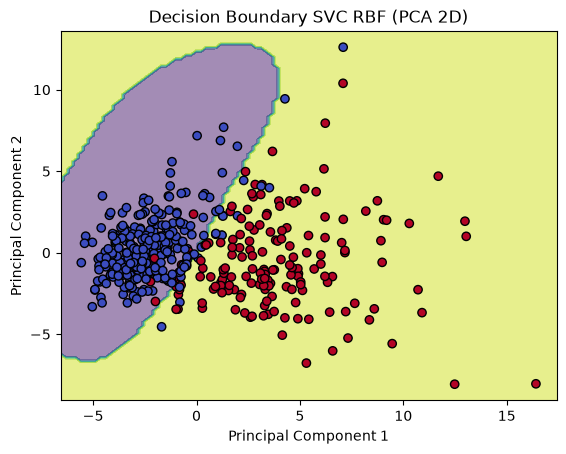

In [196]:
plt.figure(figsize=(8, 6))
# Visualisasi decision boundary untuk model SVC RBF
model_svc_rbf_pca = SVC(kernel='rbf', random_state=42, class_weight='balanced', C=1.0, gamma='scale')
model_svc_rbf_pca.fit(X_train_pca, y_train)
DecisionBoundaryDisplay.from_estimator(model_svc_rbf_pca, X_train_pca,
                                      response_method="predict", alpha=0.5)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.coolwarm)
plt.title('Decision Boundary SVC RBF (PCA 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

<Figure size 800x600 with 0 Axes>

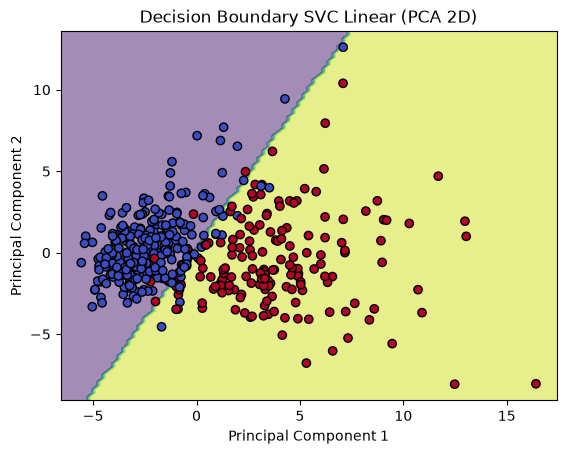

In [197]:
plt.figure(figsize=(8, 6))
# Visualisasi decision boundary untuk model SVC Linear
model_svc_linear_pca = SVC(kernel='linear', random_state=42, class_weight='balanced', C=1.0)
model_svc_linear_pca.fit(X_train_pca, y_train)
DecisionBoundaryDisplay.from_estimator(model_svc_linear_pca, X_train_pca,
                                      response_method="predict", alpha=0.5)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.coolwarm)
plt.title('Decision Boundary SVC Linear (PCA 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan:
1. **Karakteristik & Distribusi Data**: Ketidakseimbangan kelas target (62.7% Benign vs 37.3% Malignant) masih dalam kategori wajar untuk dataset medis dan tertangani dengan baik menggunakan parameter `class_weight='balanced'`.
2. **Performa Kernel Linear vs RBF**: Tidak terdapat perbedaan performa yang signifikan antara kernel Linear (Akurasi: 97.4%) dan RBF (Akurasi: 98.2%) karena sebaran data pada ruang fitur sudah terpisah dengan baik secara linear (atau mendekati linear). RBF unggul tipis di mayoritas metrik (seimbang pada presisi kelas 1 dengan selisih 0), sementara kernel Linear mendapatkan 1 poin lebih banyak pada true positive kelas 0 serta bekerja lebih efisien dengan jumlah support vectors yang jauh lebih sedikit (36 vs 69).
3. **Pengaruh Regularisasi (Nilai C) & Overfitting**: Gejala overfitting pada kernel RBF mulai tampak saat nilai C = 10, di mana akurasi training terus naik sementara akurasi testing stagnan dan mulai menurun. Nilai C = 1.0 memberikan trade-off margin dan toleransi klasifikasi yang paling optimal.

### Saran:
1. Melakukan hyperparameter tuning lebih terperinci menggunakan `GridSearchCV` pada rentang nilai C di sekitar 0.1 - 1.0 serta penyesuaian parameter `gamma`.
2. Mengeksplorasi teknik seleksi fitur (*feature selection*) untuk mereduksi 30 fitur numerik agar model lebih ringkas tanpa mendegradasi akurasi.